# Federated unlearning with auditing: results notebook

Reads only the saved outputs; it trains nothing and makes no choices.

Configuration was frozen on tuning seeds 101-103 using **validation** data (`FedOSD/results_soft/sweep_decision.json`). Every number here comes from the final seeds 31-33. Write-up: `FedOSD/RESULTS_SOFT_FEDOSD.md`.

Run from `isp/notebooks/` after `run_final.py`, `audit.run_audit`, `audit.relearn` and `audit.aggregate`.

In [1]:
import json, glob, os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = '..'
RES = os.path.join(ROOT, 'results_final')
SEEDS = [31, 32, 33]
LABELS = {'original': 'Original', 'retrain': 'Retrain (gold)', 'fedosd_hard': 'FedOSD (hard)',
          'soft_fedosd': 'Soft FedOSD (ours)', 'plain_ga': 'Plain GA',
          'posttrain_plain': 'E3: post-train, plain', 'posttrain_proj': 'E4: post-train, projected'}

## 1. Pre-registered decision (tuning seeds, validation only)

In [2]:
dec = json.load(open(os.path.join(ROOT, 'FedOSD', 'results_soft', 'sweep_decision.json')))
print(dec['verdict'])
print('eta* =', dec['eta_star'], ' G =', {k: round(v, 2) for k, v in dec['G'].items()}, ' lambda* =', dec['lambda_star'])

UNIFORM soft FedOSD (eta=0) is the main method
eta* = 1.0  G = {'pat': 2.67, 'dir0.5': 0.08, 'dir0.1': 2.28}  lambda* = 100.0


## 2. Final table (seeds 31-33, test split, mean ± std)

In [3]:
S = json.load(open(os.path.join(RES, 'final_summary.json')))['summary']
keys = {'clean_acc': 'clean acc', 'asr': 'backdoor ASR', 'forget_trig_acc': 'forget triggered acc',
        'heldout_acc': 'forget held-out acc', 'floor_test': 'worst retained client',
        'mia_attack_auc_mean': 'MIA AUC', 'distance_mean_kl_retrain_to_model': 'KL to retrain',
        'gradcam_forget_train_trig_energy_in_trigger_mean': 'CAM energy in trigger'}
fmt = lambda v: f'{v[0]:.3f} ± {v[1]:.3f}' if v[0] < 2 else f'{v[0]:.2f} ± {v[1]:.2f}'
df = pd.DataFrame({LABELS[m]: {lab: fmt(S[m][k]) for k, lab in keys.items() if k in S[m]} for m in S}).T
df

,clean acc,backdoor ASR,forget triggered acc,forget held-out acc,worst retained client,MIA AUC,KL to retrain,CAM energy in trigger
Original,49.31 ± 0.36,84.30 ± 0.42,93.40 ± 0.58,48.44 ± 5.86,nan ± nan,0.496 ± 0.014,0.563 ± 0.008,0.280 ± 0.003
Retrain (gold),59.59 ± 0.15,4.58 ± 1.42,3.54 ± 2.79,53.17 ± 2.48,45.28 ± 3.25,0.493 ± 0.015,0.000 ± 0.000,0.030 ± 0.013
FedOSD (hard),42.72 ± 1.01,1.848 ± 1.307,0.213 ± 0.152,39.17 ± 5.33,23.56 ± 2.78,0.504 ± 0.005,0.753 ± 0.051,0.487 ± 0.089
Soft FedOSD (ours),42.17 ± 1.05,1.772 ± 1.253,0.200 ± 0.145,37.78 ± 5.74,23.17 ± 3.42,0.505 ± 0.004,0.771 ± 0.054,0.492 ± 0.084
Plain GA,34.29 ± 2.14,0.306 ± 0.239,0.027 ± 0.019,2.78 ± 2.18,2.56 ± 1.89,0.513 ± 0.012,1.538 ± 0.305,0.387 ± 0.131
"E3: post-train, plain",51.59 ± 0.44,6.62 ± 2.81,4.13 ± 1.31,45.61 ± 3.62,33.44 ± 1.98,0.497 ± 0.016,0.503 ± 0.010,0.437 ± 0.101
"E4: post-train, projected",51.59 ± 0.49,6.43 ± 2.85,3.85 ± 1.17,45.61 ± 3.62,33.33 ± 1.91,0.497 ± 0.016,0.504 ± 0.010,0.436 ± 0.100


## 3. Relearning test

An attacker fine-tunes each model on 32 triggered forget-client images (plain SGD, lr 0.01). A model that truly forgot should relearn the backdoor no faster than retrain.

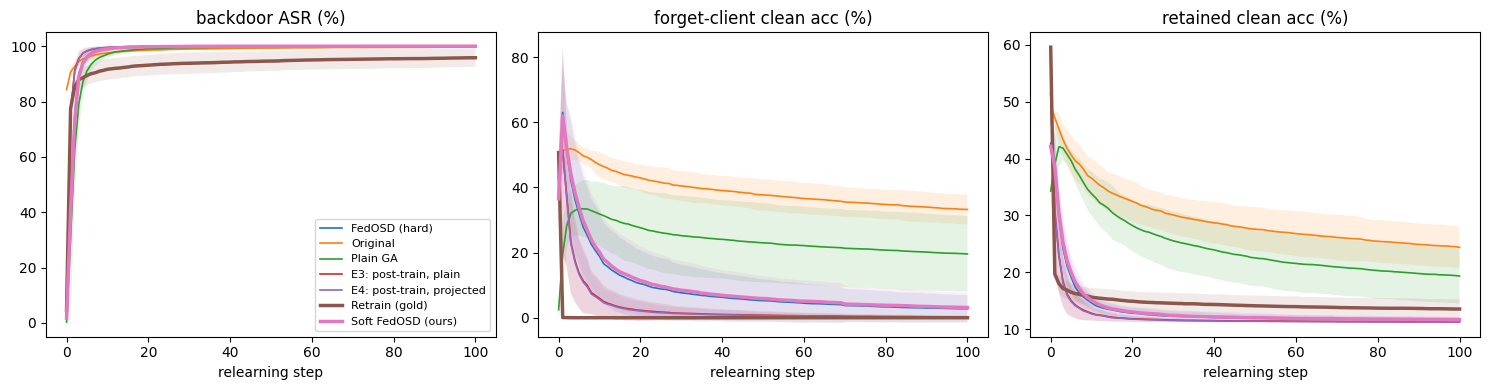

,asr_10,asr_end,steps_to_50
original,"[97.57355054219563, 0.8680947348760021]","[99.68012968699138, 0.18775563973537668]","[0, 0, 0]"
retrain,"[91.66579246520996, 3.070149490921926]","[95.82949876785278, 2.6563973009876745]","[1, 1, 1]"
fedosd_hard,"[99.12416537602742, 0.70192154968923]","[100.0, 0.0]","[1, 2, 2]"
soft_fedosd,"[99.00599320729573, 0.7539107615676061]","[100.0, 0.0]","[1, 2, 2]"
plain_ga,"[97.09405899047852, 1.1222747150989487]","[99.93743499120076, 0.05106384993715608]","[1, 2, 3]"
posttrain_plain,"[99.51325456301372, 0.33485736929944304]","[100.0, 0.0]","[1, 1, 1]"
posttrain_proj,"[99.54108397165935, 0.3108442126397228]","[100.0, 0.0]","[1, 1, 1]"


In [4]:
rows = [dict(r, seed=s) for s in SEEDS if os.path.exists(p := os.path.join(RES, f'seed{s}', 'relearn.json')) for r in json.load(open(p))]
R = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, title in zip(axes, ['asr', 'forget_acc', 'clean_acc'], ['backdoor ASR (%)', 'forget-client clean acc (%)', 'retained clean acc (%)']):
    for m, g in R.groupby('model'):
        c = g.groupby('round')[key].agg(['mean', 'std'])
        ax.plot(c.index, c['mean'], label=LABELS.get(m, m), lw=2.5 if m in ('soft_fedosd', 'retrain') else 1.2)
        ax.fill_between(c.index, c['mean'] - c['std'], c['mean'] + c['std'], alpha=0.12)
    ax.set_title(title); ax.set_xlabel('relearning step')
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
if os.path.exists(p := os.path.join(RES, 'relearn_overall.json')):
    display(pd.DataFrame(json.load(open(p))['per_model']).T)

## 4. Grad-CAM (one figure per seed, produced by `audit.run_audit`)

**seed 31**

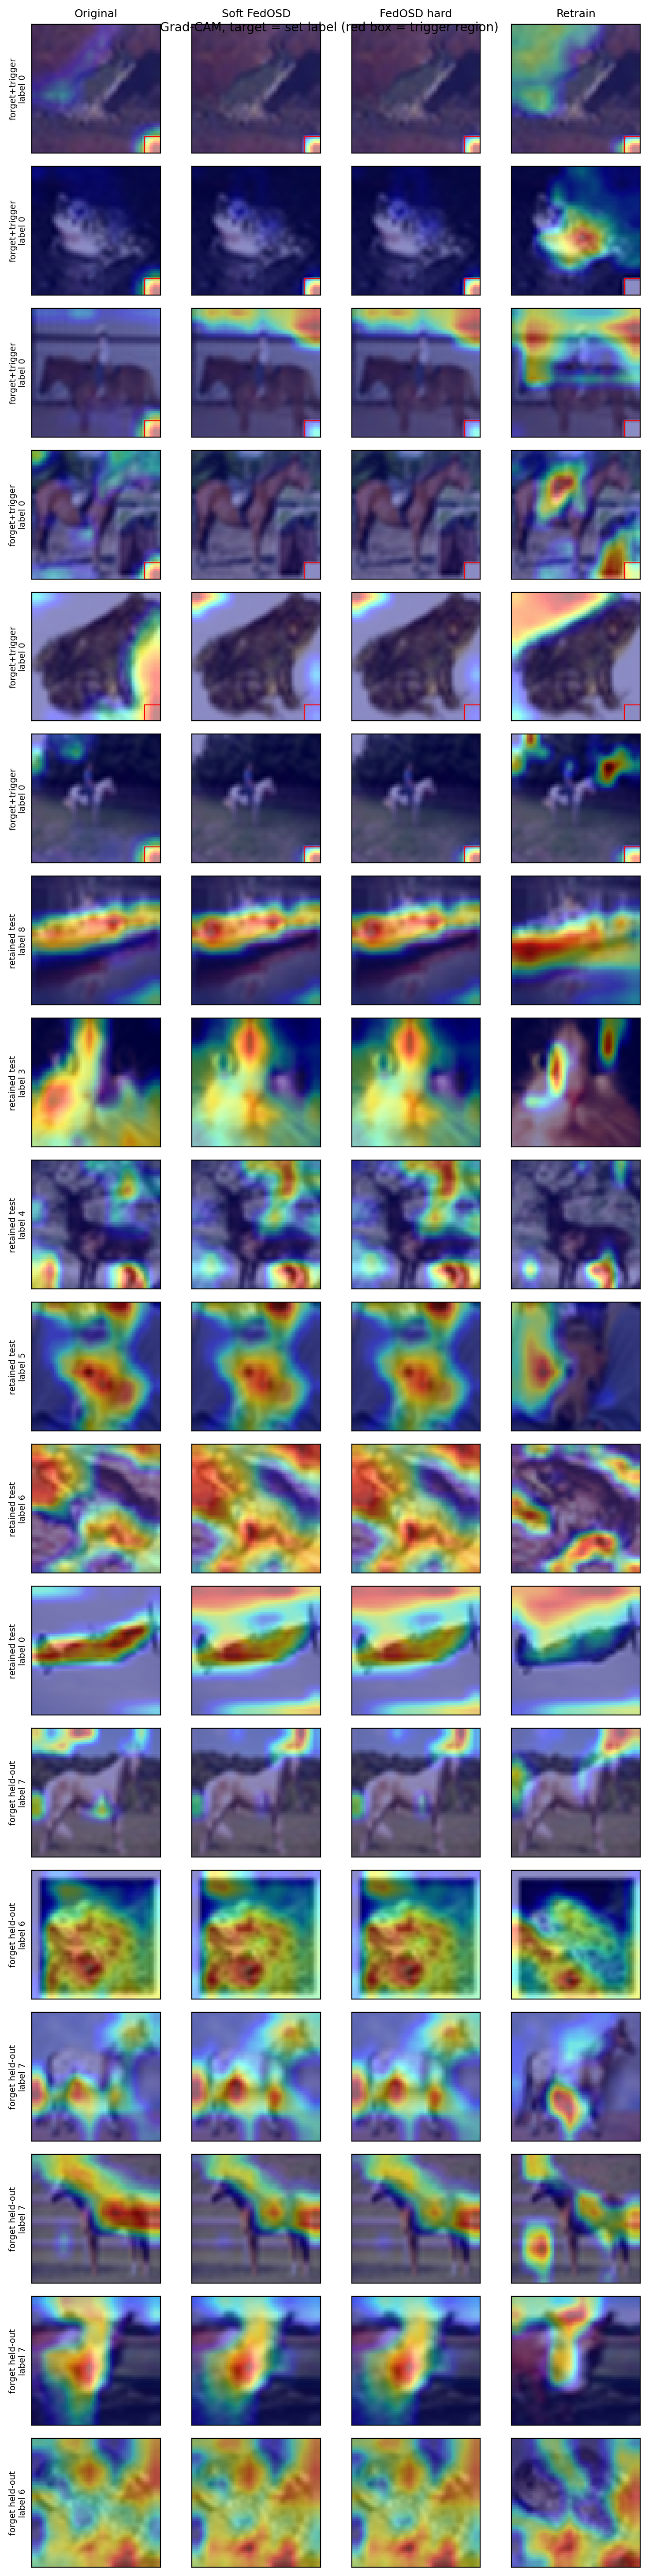

**seed 32**

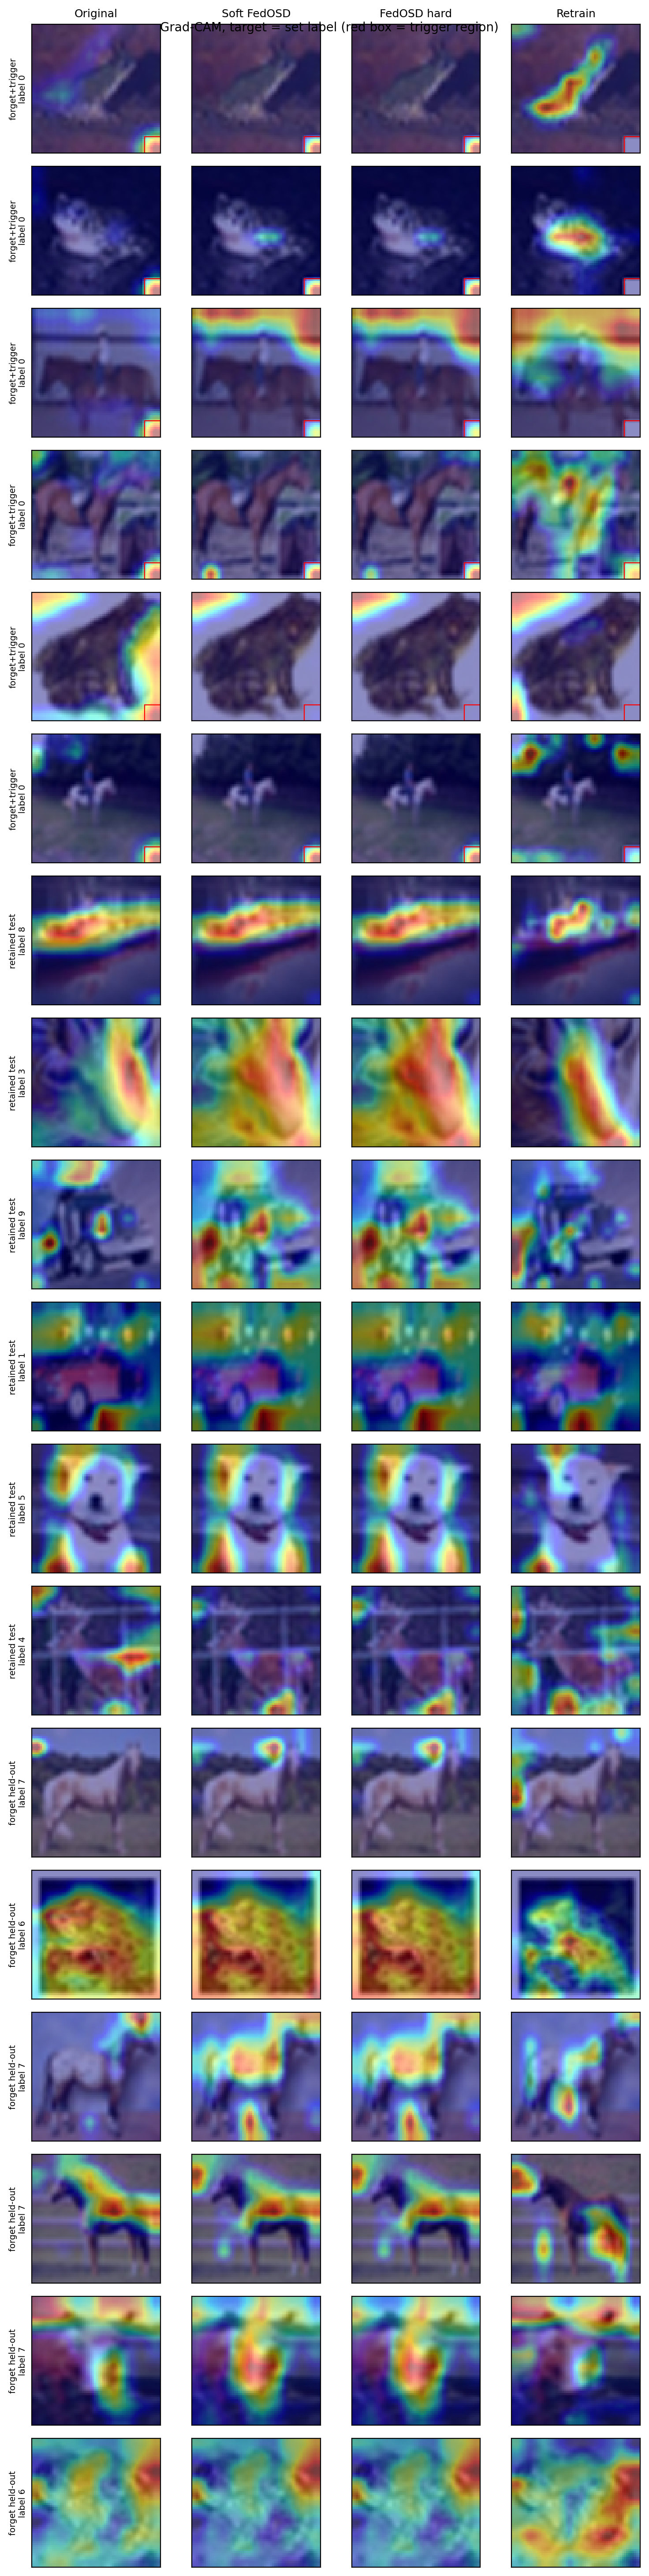

**seed 33**

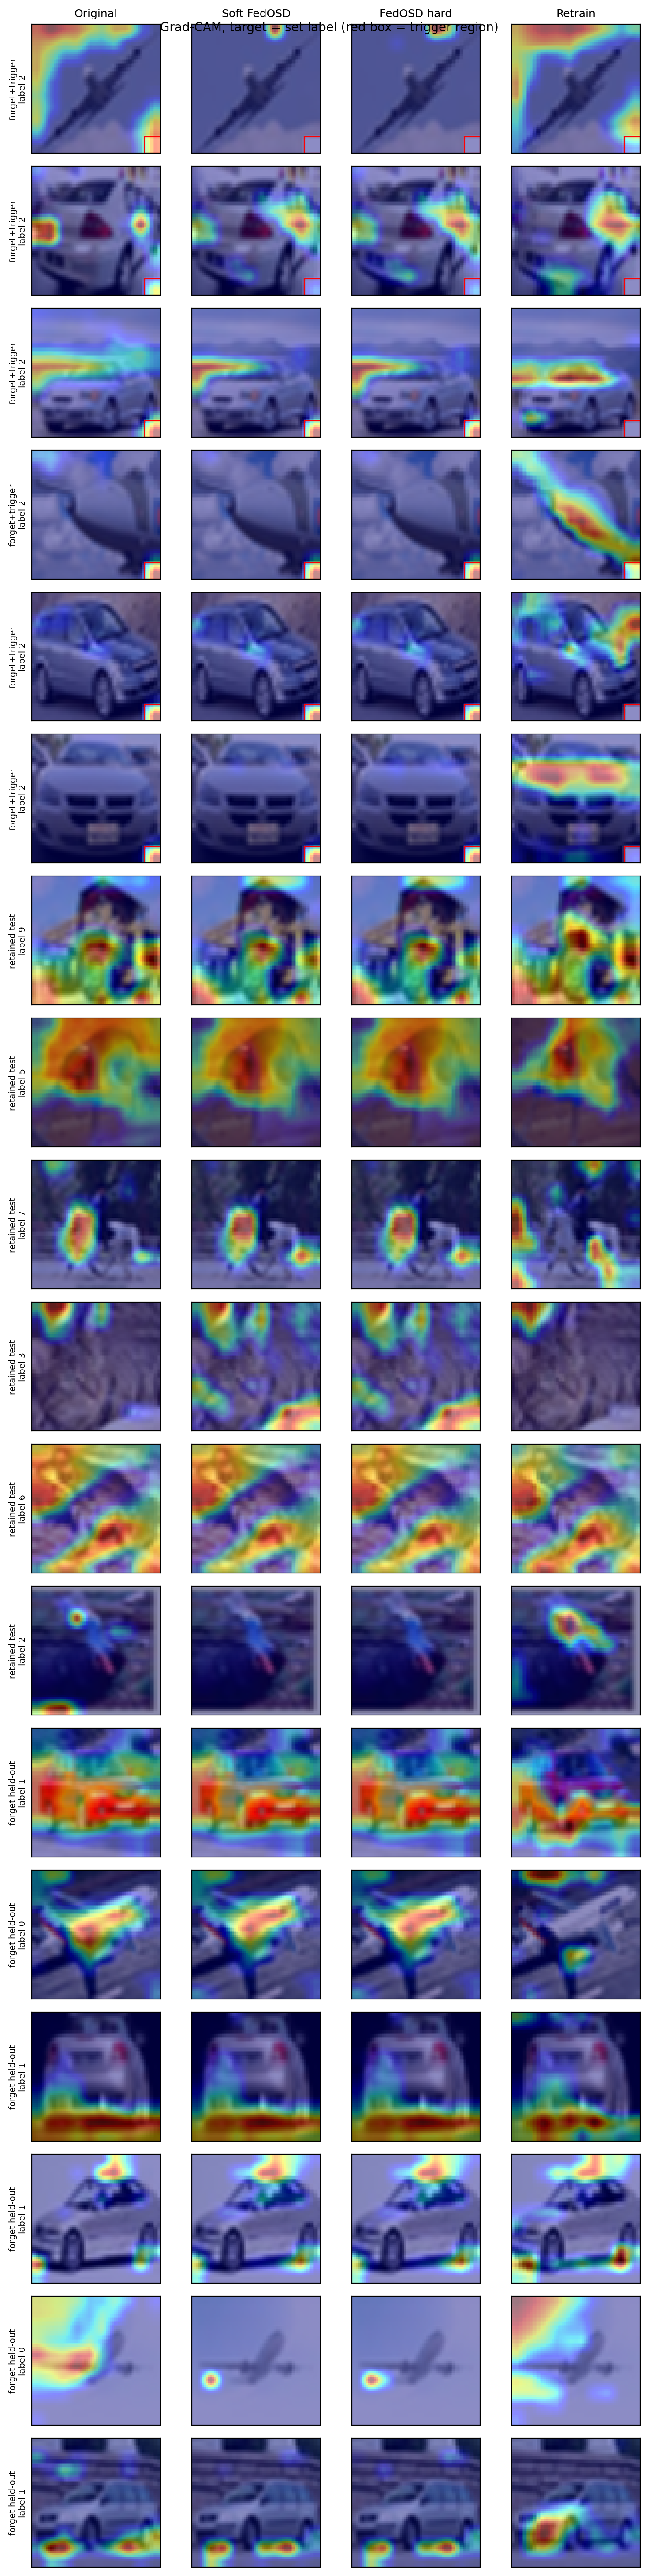

In [5]:
for s in SEEDS:
    p = os.path.join(RES, f'seed{s}', 'audit_gradcam.png')
    if os.path.exists(p):
        display(Markdown(f'**seed {s}**')); display(Image(p))

## 5. Live check on one bundle

This reloads the exported models and recomputes predictions on a few triggered test images.

In [6]:
import sys, importlib.util, torch
B = os.path.join(ROOT, 'bundles', 'seed31')
spec = importlib.util.spec_from_file_location('bundle_api', os.path.join(B, 'bundle_api.py'))
api = importlib.util.module_from_spec(spec); spec.loader.exec_module(api)
X, y = api.get_set('trigger_test')
idx = torch.arange(8)
with torch.no_grad():
    preds = {LABELS.get(m, m): api.load_model(m).eval()(X[idx]).argmax(1).tolist() for m in api.available_models()}
print('backdoor target label:', y[idx].tolist())
pd.DataFrame(preds, index=[f'img{i}' for i in idx.tolist()]).T

backdoor target label: [0, 0, 0, 0, 0, 0, 0, 0]


,img0,img1,img2,img3,img4,img5,img6,img7
FedOSD (hard),1,1,5,5,1,1,1,1
Original,0,0,5,5,0,0,0,0
Plain GA,5,1,9,5,1,1,1,5
"E3: post-train, plain",0,1,5,5,1,0,1,0
"E4: post-train, projected",0,1,5,5,1,0,1,0
Retrain (gold),5,4,5,3,5,4,5,4
Soft FedOSD (ours),1,1,5,5,1,1,1,1
